# XAUUSD Macro Research — Gold COT + DXY COT + Treasury Yields

Automated daily/weekly updates from official CFTC and FRED data, plus DXY price history from Yahoo Finance. The notebook displays calculation tables, four charts, and a **final compact macro summary**.

**Exact output windows**
- **Gold COT:** 52 *weekly reports* (COMEX Gold, Disaggregated Futures Only, **Managed Money**).
- **USD Index COT:** 52 *weekly reports* (ICE USD Index, Legacy Futures Only, **Non-Commercial**).
- **US Treasury yields:** 252 valid *daily observations* for US 2Y, US 10Y, and US 10Y real yield.
- **DXY price:** 252 daily closes, retained to help interpret both COT datasets.

**Method:** The current observation is included in each 52-report / 252-observation Z-score and COT Index window. Downloading older observations first lets all displayed historical rows have valid rolling statistics whenever sufficient history exists. For a current-vs-*previous* 52-week benchmark, one more past observation would be required.

**Important:** A Gold Managed Money position and a USD Index Non-Commercial position are **not the same trader classification**. COT positions normally describe Tuesday and are published Friday; this notebook uses an *approximate* Friday release check, not an exact historical publication calendar. Yield changes are in **percentage points (pp)**, DXY changes are **percent returns**, and COT weekly changes are **contracts**. No percentage, Z-score, or index here is a predictive trading probability.

Run **Kernel → Restart Kernel and Run All Cells**. Close the workbook in Excel before running.

## 1. Settings and imports

In [1]:
from pathlib import Path
from io import StringIO
import os
import warnings

import numpy as np
import pandas as pd
import requests
from IPython.display import display

try:
    import yfinance as yf
except ImportError as exc:
    raise ImportError("Install: python -m pip install -U yfinance") from exc

# From CMD: cd /d "D:\Trading DATA\MacroTrading"; .venv\Scripts\activate; python -m jupyterlab
folder_override = os.getenv("MACRO_TRADING_DIR", "").strip()
BASE_DIR = Path(folder_override) if folder_override else Path.cwd()
if BASE_DIR.name.lower() == "notebooks":
    BASE_DIR = BASE_DIR.parent
BASE_DIR = BASE_DIR.resolve()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "output"
DATA_DIR.mkdir(exist_ok=True, parents=True)
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
EXCEL_FILE = OUTPUT_DIR / "Yield_Analysis.xlsx"

AS_OF_DATE = None        # Optional: "2026-10-12"; None uses last completed US session
SAVE_EXCEL = True        # False = don't write Excel
SHOW_TABLES = True
SHOW_CHARTS = True
DAILY_WINDOW = 252
COT_WINDOW = 52
CFTC_FETCH_LIMIT = 180  # Older reports are calculation history, NOT exported
DXY_TICKER = "DX-Y.NYB"
FRED_CODES = ("DGS2", "DGS10", "DFII10")

if AS_OF_DATE is None:
    ny_now = pd.Timestamp.now(tz="America/New_York")
    cutoff = ny_now.normalize().tz_localize(None)
    # Exclude an in-progress US market day.
    if ny_now.hour < 18:
        cutoff -= pd.Timedelta(days=1)
else:
    cutoff = pd.Timestamp(AS_OF_DATE).normalize()

if cutoff > pd.Timestamp.now(tz="UTC").tz_localize(None).normalize():
    raise ValueError("AS_OF_DATE cannot be in the future")

print("Project:", BASE_DIR)
print("Analysis cutoff:", cutoff.date())

Project: D:\Trading DATA\MacroTrading
Analysis cutoff: 2026-10-13


## 2. US Treasury yields — 252 valid observations

In [2]:
FRED_CSV_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv"

def fetch_fred(code):
    response = requests.get(FRED_CSV_URL, params={"id": code}, timeout=60)
    response.raise_for_status()
    source = pd.read_csv(StringIO(response.text))
    if source.shape[1] != 2:
        raise ValueError(f"Unexpected FRED columns for {code}: {source.columns.tolist()}")
    source.columns = ["date", code]
    source["date"] = pd.to_datetime(source["date"], errors="coerce").dt.normalize()
    source[code] = pd.to_numeric(source[code], errors="coerce")
    return (source.dropna(subset=["date", code])
                  .loc[lambda x: x["date"] <= cutoff]
                  .sort_values("date").drop_duplicates("date", keep="last")
                  .reset_index(drop=True))

parts = [fetch_fred(code) for code in FRED_CODES]
all_yields = parts[0]
for part in parts[1:]:
    all_yields = all_yields.merge(part, on="date", how="inner", validate="one_to_one")
all_yields = all_yields.sort_values("date").reset_index(drop=True)
if len(all_yields) < DAILY_WINDOW:
    raise ValueError(f"Need {DAILY_WINDOW} common valid yield dates, found {len(all_yields)}")

for name in FRED_CODES:
    series = all_yields[name]
    window = series.rolling(DAILY_WINDOW, min_periods=DAILY_WINDOW)
    all_yields[f"{name}_Average"] = window.mean()
    all_yields[f"{name}_Std"] = window.std(ddof=1)
    all_yields[f"{name}_Zscore"] = (
        (series - all_yields[f"{name}_Average"]) /
        all_yields[f"{name}_Std"].replace(0, np.nan)
    )
    all_yields[f"{name}_5D_Change"] = series.diff(5)
    all_yields[f"{name}_20D_Change"] = series.diff(20)

yields = all_yields.tail(DAILY_WINDOW).reset_index(drop=True)
latest_yield = yields.iloc[-1]
if latest_yield[[f"{name}_Zscore" for name in FRED_CODES]].isna().any():
    raise ValueError("Latest yield Z-score unavailable (no price variation or missing history)")
print(f"US Treasury data: {len(yields)} daily observations, through {latest_yield['date'].date()}")

US Treasury data: 252 daily observations, through 2026-10-09


In [3]:
if SHOW_TABLES:
    columns = ["date"] + [v for c in FRED_CODES for v in
               (c, f"{c}_Zscore", f"{c}_5D_Change", f"{c}_20D_Change")]
    preview = yields[columns].tail(10)
    print("YIELD CALCULATIONS — latest 10 dates (yield %; changes in pp)")
    display(preview.style.format({c: "{:+.3f}" if "Change" in c or "Zscore" in c else "{:.3f}"
                                  for c in preview.columns if c != "date"}, na_rep="—"))

YIELD CALCULATIONS — latest 10 dates (yield %; changes in pp)


,date,DGS2,DGS2_Zscore,DGS2_5D_Change,DGS2_20D_Change,DGS10,DGS10_Zscore,DGS10_5D_Change,DGS10_20D_Change,DFII10,DFII10_Zscore,DFII10_5D_Change,DFII10_20D_Change
242,2026-09-28 00:00:00,4.920,+2.949,+0.160,+0.580,5.240,+3.237,+0.280,+0.510,2.900,+3.212,+0.280,+0.480
243,2026-09-29 00:00:00,4.890,+2.809,+0.180,+0.550,5.260,+3.228,+0.300,+0.510,2.910,+3.173,+0.280,+0.470
244,2026-09-30 00:00:00,4.880,+2.729,+0.030,+0.490,5.290,+3.252,+0.180,+0.500,2.930,+3.170,+0.170,+0.490
245,2026-10-01 00:00:00,4.780,+2.422,-0.090,+0.390,5.240,+3.008,+0.060,+0.450,2.880,+2.926,+0.030,+0.430
246,2026-10-02 00:00:00,4.830,+2.512,+0.020,+0.490,5.280,+3.075,+0.110,+0.510,2.920,+3.003,+0.090,+0.500
247,2026-10-05 00:00:00,4.840,+2.496,-0.080,+0.470,5.310,+3.105,+0.070,+0.530,2.950,+3.041,+0.050,+0.520
248,2026-10-06 00:00:00,4.790,+2.332,-0.100,+0.400,5.270,+2.910,+0.010,+0.470,2.910,+2.846,+0.000,+0.480
249,2026-10-07 00:00:00,4.770,+2.248,-0.110,+0.340,5.280,+2.883,-0.010,+0.450,2.920,+2.824,-0.010,+0.460
250,2026-10-08 00:00:00,4.750,+2.167,-0.030,+0.190,5.220,+2.640,-0.020,+0.270,2.870,+2.609,-0.010,+0.320
251,2026-10-09 00:00:00,4.800,+2.260,-0.030,+0.170,5.240,+2.655,-0.040,+0.280,2.910,+2.693,-0.010,+0.310


## 3. CFTC API helper — download and calculate both 52-week COT datasets

In [4]:
def fetch_cftc(dataset_id, contract_code, contract_label, exchange_keyword):
    """Public token-free Socrata v2 endpoint. The report family is set by dataset_id."""
    url = f"https://publicreporting.cftc.gov/resource/{dataset_id}.json"
    params = {
        "$where": f"cftc_contract_market_code = '{contract_code}'",
        "$order": "report_date_as_yyyy_mm_dd DESC",
        "$limit": CFTC_FETCH_LIMIT
    }
    response = requests.get(url, params=params,
                            headers={"Accept": "application/json"}, timeout=90)
    try:
        response.raise_for_status()
    except requests.HTTPError as exc:
        raise RuntimeError(
            f"CFTC API failed for {contract_label}: HTTP {response.status_code}. "
            f"{response.text[:220]}"
        ) from exc
    records = response.json()
    if not isinstance(records, list) or not records:
        raise ValueError(f"No CFTC records returned for {contract_label}")
    frame = pd.DataFrame(records)
    required = {"report_date_as_yyyy_mm_dd", "cftc_contract_market_code",
                "noncomm_positions_long_all", "noncomm_positions_short_all"} if dataset_id == "6dca-aqww" else {
                "report_date_as_yyyy_mm_dd", "cftc_contract_market_code",
                "m_money_positions_long_all", "m_money_positions_short_all"}
    missing = required - set(frame.columns)
    if missing:
        raise KeyError(f"CFTC {contract_label} is missing fields: {sorted(missing)}")

    mask = frame["cftc_contract_market_code"].astype(str).str.zfill(6).eq(contract_code)
    if "contract_market_name" in frame:
        mask &= frame["contract_market_name"].astype(str).str.strip().str.upper().eq(contract_label)
    if "market_and_exchange_names" in frame:
        mask &= frame["market_and_exchange_names"].astype(str).str.contains(
            exchange_keyword, case=False, regex=False, na=False)
    frame = frame.loc[mask].copy()
    if frame.empty:
        raise ValueError(f"No matching {contract_label} contracts after exchange/name verification")
    return frame


def build_cot(raw, long_field, short_field, label, category):
    def numeric(field):
        return pd.to_numeric(raw[field].astype("string").str.replace(",", "", regex=False),
                             errors="coerce")

    complete = pd.DataFrame({
        "Date": pd.to_datetime(raw["report_date_as_yyyy_mm_dd"], utc=True, errors="coerce")
                  .dt.tz_localize(None).dt.normalize(),
        "Long": numeric(long_field),
        "Short": numeric(short_field)
    })
    complete["Earliest_Normal_Release"] = complete["Date"] + pd.Timedelta(days=3)
    complete = (complete.dropna(subset=["Date", "Long", "Short"])
                .loc[lambda x: x["Earliest_Normal_Release"] <= cutoff]
                .sort_values("Date").drop_duplicates("Date", keep="last")
                .reset_index(drop=True))
    if len(complete) < COT_WINDOW:
        raise ValueError(f"{label}: only {len(complete)} eligible reports; need {COT_WINDOW}")

    net = complete["Long"] - complete["Short"]
    complete["Net_Position"] = net
    complete["Weekly_Change"] = net.diff()
    complete["Net_Change_4W"] = net.diff(4)
    window = net.rolling(COT_WINDOW, min_periods=COT_WINDOW)
    complete["COT_Average_52W"] = window.mean()
    complete["COT_Std_52W"] = window.std(ddof=1)
    complete["COT_Zscore"] = (
        (net - complete["COT_Average_52W"]) /
        complete["COT_Std_52W"].replace(0, np.nan))
    complete["COT_Min_52W"] = window.min()
    complete["COT_Max_52W"] = window.max()
    complete["COT_Index"] = 100 * (
        (net - complete["COT_Min_52W"]) /
        (complete["COT_Max_52W"] - complete["COT_Min_52W"]).replace(0, np.nan))
    total = (complete["Long"] + complete["Short"]).replace(0, np.nan)
    complete["Long_Percent"] = 100 * complete["Long"] / total
    complete["Short_Percent"] = 100 * complete["Short"] / total
    complete["Net_Percent"] = 100 * net / total
    complete["Category"] = category
    output = complete.tail(COT_WINDOW).reset_index(drop=True)
    if output.iloc[-1][["COT_Zscore", "COT_Index"]].isna().any():
        raise ValueError(f"{label}: latest COT Z-score/Index undefined")
    print(f"{label}: {len(output)} weekly reports, latest position date {output.iloc[-1]['Date'].date()}")
    return output


def show_cot_table(frame, title):
    if not SHOW_TABLES:
        return
    colnames = ["Date", "Long", "Short", "Net_Position", "Weekly_Change",
                "Long_Percent", "Short_Percent", "Net_Percent", "COT_Zscore", "COT_Index"]
    preview = frame[colnames].tail(12)
    print(title, "— latest 12 of 52 reports")
    display(preview.style.format({
        "Long": "{:,.0f}", "Short": "{:,.0f}",
        "Net_Position": "{:+,.0f}", "Weekly_Change": "{:+,.0f}",
        "Long_Percent": "{:.2f}%", "Short_Percent": "{:.2f}%",
        "Net_Percent": "{:+.2f}%", "COT_Zscore": "{:+.2f}",
        "COT_Index": "{:.2f}"
    }, na_rep="—"))

## 4. Gold COT — 52 weekly reports (COMEX Managed Money)

In [5]:
gold_raw = fetch_cftc(
    "72hh-3qpy", "088691", "GOLD", "COMMODITY EXCHANGE"
)
cot = build_cot(
    gold_raw, "m_money_positions_long_all", "m_money_positions_short_all",
    "Gold COT", "Disaggregated Futures Only — Managed Money"
)
latest_cot = cot.iloc[-1]
show_cot_table(cot, "GOLD COT — MANAGED MONEY")

Gold COT: 52 weekly reports, latest position date 2026-10-06
GOLD COT — MANAGED MONEY — latest 12 of 52 reports


,Date,Long,Short,Net_Position,Weekly_Change,Long_Percent,Short_Percent,Net_Percent,COT_Zscore,COT_Index
40,2026-07-21 00:00:00,"141,487","16,656","+124,831","+4,052",89.47%,10.53%,+78.94%,+0.39,47.55
41,2026-07-28 00:00:00,"135,093","15,298","+119,795","-5,036",89.83%,10.17%,+79.66%,+0.18,40.73
42,2026-08-04 00:00:00,"139,809","9,043","+130,766","+10,971",93.92%,6.08%,+87.85%,+0.72,55.60
43,2026-08-11 00:00:00,"148,634","10,972","+137,662","+6,896",93.13%,6.87%,+86.25%,+1.07,64.95
44,2026-08-18 00:00:00,"154,595","12,947","+141,648","+3,986",92.27%,7.73%,+84.54%,+1.25,70.35
45,2026-08-25 00:00:00,"159,819","15,072","+144,747","+3,099",91.38%,8.62%,+82.76%,+1.39,74.55
46,2026-09-01 00:00:00,"149,721","12,950","+136,771","-7,976",92.04%,7.96%,+84.08%,+1.07,63.74
47,2026-09-08 00:00:00,"145,804","10,832","+134,972","-1,799",93.08%,6.92%,+86.17%,+1.06,63.87
48,2026-09-15 00:00:00,"142,394","9,278","+133,116","-1,856",93.88%,6.12%,+87.77%,+1.04,61.25
49,2026-09-22 00:00:00,"135,699","8,310","+127,389","-5,727",94.23%,5.77%,+88.46%,+0.81,67.84


## 5. DXY COT — 52 weekly reports (ICE USD Index Non-Commercial)

In [6]:
# USD Index futures ≠ the DXY cash/index price series.
# This COT report is Legacy Futures Only; do NOT relabel its participants as Managed Money.
dxy_cot_raw = fetch_cftc(
    "6dca-aqww", "098662", "USD INDEX", "ICE FUTURES"
)
dxy_cot = build_cot(
    dxy_cot_raw, "noncomm_positions_long_all", "noncomm_positions_short_all",
    "DXY COT", "Legacy Futures Only — Non-Commercial"
)
latest_dxy_cot = dxy_cot.iloc[-1]
show_cot_table(dxy_cot, "USD INDEX COT — NON-COMMERCIAL")

DXY COT: 52 weekly reports, latest position date 2026-10-06
USD INDEX COT — NON-COMMERCIAL — latest 12 of 52 reports


,Date,Long,Short,Net_Position,Weekly_Change,Long_Percent,Short_Percent,Net_Percent,COT_Zscore,COT_Index
40,2026-07-21 00:00:00,"33,270","17,656","+15,614","+2,441",65.33%,34.67%,+30.66%,+2.07,100.00
41,2026-07-28 00:00:00,"35,339","18,142","+17,197","+1,583",66.08%,33.92%,+32.16%,+2.11,100.00
42,2026-08-04 00:00:00,"35,247","12,748","+22,499","+5,302",73.44%,26.56%,+46.88%,+2.45,100.00
43,2026-08-11 00:00:00,"32,651","11,242","+21,409","-1,090",74.39%,25.61%,+48.78%,+2.18,97.19
44,2026-08-18 00:00:00,"29,582","10,503","+19,079","-2,330",73.80%,26.20%,+47.60%,+1.85,91.20
45,2026-08-25 00:00:00,"29,042","10,360","+18,682",-397,73.71%,26.29%,+47.41%,+1.72,90.17
46,2026-09-01 00:00:00,"28,240","11,215","+17,025","-1,657",71.58%,28.42%,+43.15%,+1.50,85.91
47,2026-09-08 00:00:00,"28,407","10,803","+17,604",+579,72.45%,27.55%,+44.90%,+1.48,87.40
48,2026-09-15 00:00:00,"25,971","15,378","+10,593","-7,011",62.81%,37.19%,+25.62%,+0.85,69.35
49,2026-09-22 00:00:00,"27,768","17,438","+10,330",-263,61.43%,38.57%,+22.85%,+0.79,68.67


## 6. DXY price — 252 daily closes (Yahoo Finance)

In [7]:
prices = yf.Ticker(DXY_TICKER).history(period="3y", interval="1d", auto_adjust=False)
if prices.empty or "Close" not in prices:
    raise RuntimeError(f"Yahoo Finance returned no DXY daily closes for {DXY_TICKER}")
idx = pd.to_datetime(prices.index)
if idx.tz is not None:
    idx = idx.tz_localize(None)  # Preserve displayed session date
all_dxy = pd.DataFrame({
    "Date": idx.normalize(),
    "DXY": pd.to_numeric(prices["Close"].to_numpy(), errors="coerce")
})
all_dxy = (all_dxy.dropna(subset=["Date", "DXY"])
           .loc[lambda x: x["Date"] <= cutoff]
           .sort_values("Date").drop_duplicates("Date", keep="last")
           .reset_index(drop=True))
if len(all_dxy) < DAILY_WINDOW:
    raise ValueError(f"DXY price has only {len(all_dxy)} eligible closes; need {DAILY_WINDOW}")
s = all_dxy["DXY"]
w = s.rolling(DAILY_WINDOW, min_periods=DAILY_WINDOW)
all_dxy["DXY_Mean_52W"] = w.mean()
all_dxy["DXY_Std_52W"] = w.std(ddof=1)
all_dxy["DXY_Zscore"] = (s - all_dxy["DXY_Mean_52W"]) / all_dxy["DXY_Std_52W"].replace(0, np.nan)
all_dxy["DXY_5D_Percent"] = 100 * s.pct_change(5)
all_dxy["DXY_20D_Percent"] = 100 * s.pct_change(20)
dxy = all_dxy.tail(DAILY_WINDOW).reset_index(drop=True)
latest_dxy = dxy.iloc[-1]
if pd.isna(latest_dxy["DXY_Zscore"]):
    raise ValueError("DXY current Z-score unavailable")
print(f"DXY price: {len(dxy)} daily closes, through {latest_dxy['Date'].date()}")
if SHOW_TABLES:
    view = dxy[["Date", "DXY", "DXY_5D_Percent", "DXY_20D_Percent", "DXY_Zscore"]].tail(10)
    display(view.style.format({
        "DXY": "{:.3f}", "DXY_5D_Percent": "{:+.2f}%",
        "DXY_20D_Percent": "{:+.2f}%", "DXY_Zscore": "{:+.2f}"
    }, na_rep="—"))

DXY price: 252 daily closes, through 2026-10-13


,Date,DXY,DXY_5D_Percent,DXY_20D_Percent,DXY_Zscore
242,2026-09-30 00:00:00,101.450,+0.35%,+1.79%,+1.99
243,2026-10-01 00:00:00,102.100,+0.80%,+2.55%,+2.53
244,2026-10-02 00:00:00,101.930,+0.95%,+2.96%,+2.35
245,2026-10-05 00:00:00,102.170,+0.96%,+3.04%,+2.52
246,2026-10-06 00:00:00,101.830,+0.45%,+3.03%,+2.20
247,2026-10-07 00:00:00,102.240,+0.78%,+3.51%,+2.51
248,2026-10-08 00:00:00,102.140,+0.04%,+3.08%,+2.39
249,2026-10-09 00:00:00,102.210,+0.27%,+3.12%,+2.41
250,2026-10-12 00:00:00,102.580,+0.40%,+3.14%,+2.67
251,2026-10-13 00:00:00,102.215,+0.38%,+2.57%,+2.33


## 7. Charts — yields, Gold COT, DXY price, DXY COT

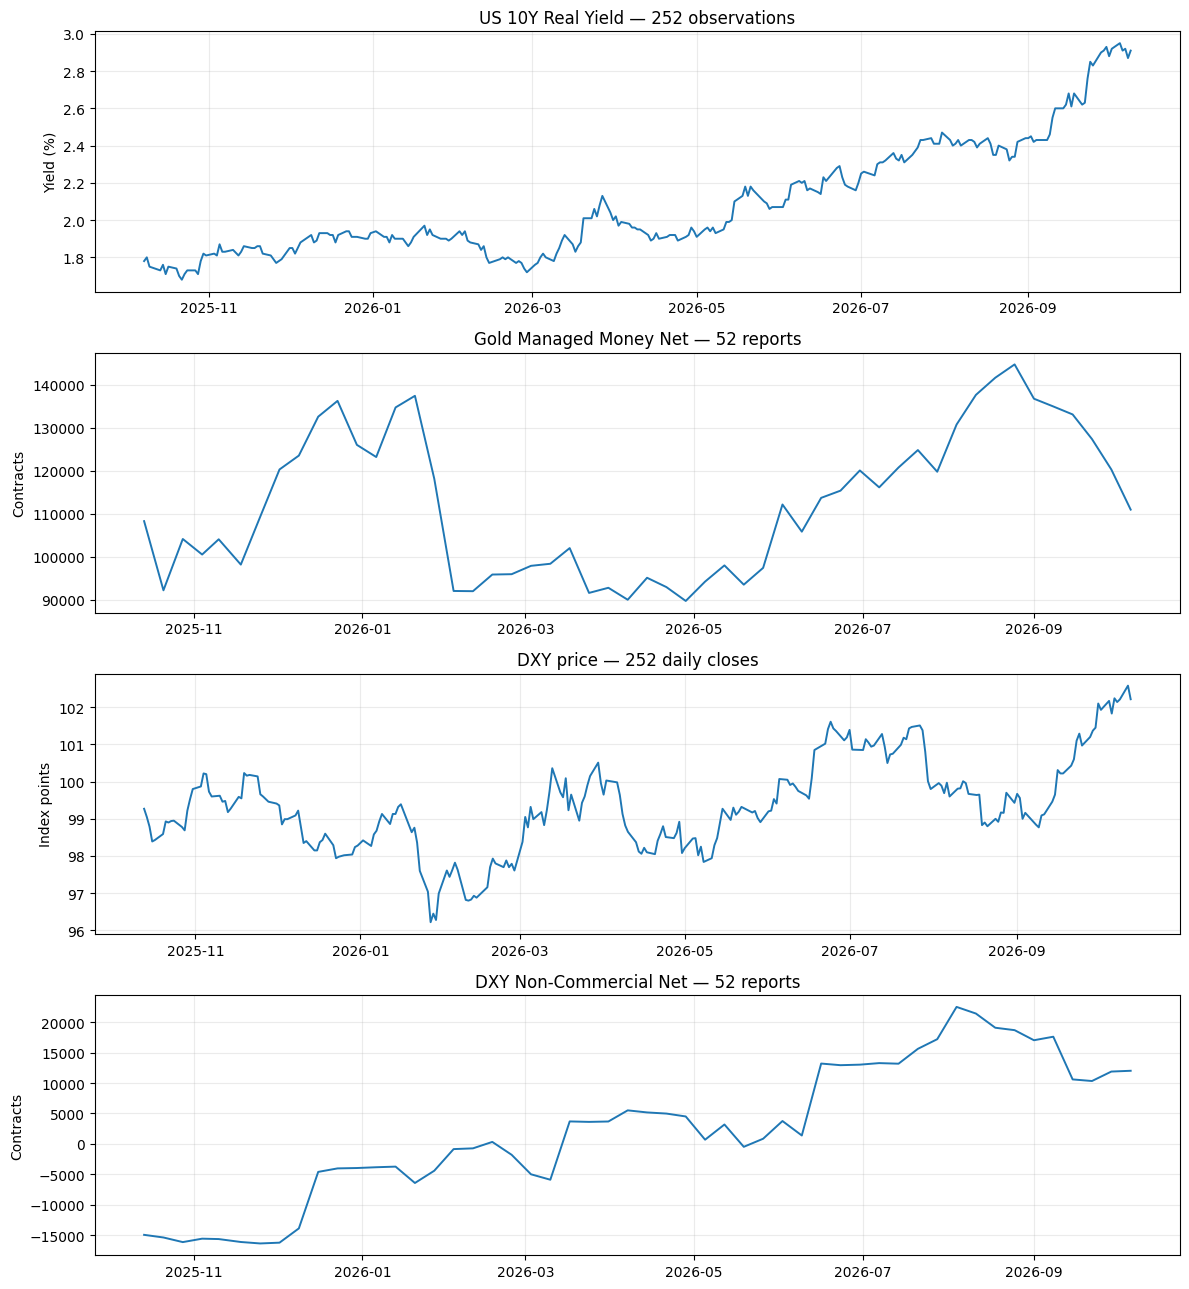

In [8]:
if SHOW_CHARTS:
    import matplotlib.pyplot as plt
    chart_specs = [
        (yields["date"], yields["DFII10"], "US 10Y Real Yield — 252 observations", "Yield (%)"),
        (cot["Date"], cot["Net_Position"], "Gold Managed Money Net — 52 reports", "Contracts"),
        (dxy["Date"], dxy["DXY"], "DXY price — 252 daily closes", "Index points"),
        (dxy_cot["Date"], dxy_cot["Net_Position"], "DXY Non-Commercial Net — 52 reports", "Contracts")
    ]
    fig, axes = plt.subplots(4, 1, figsize=(12, 13))
    for ax, (dates, values, name, unit) in zip(axes, chart_specs):
        ax.plot(dates, values, linewidth=1.4)
        ax.set_title(name)
        ax.set_ylabel(unit)
        ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

## 8. Build summary table (also used for Excel)

In [9]:
summary_rows = []
for symbol, name in [
    ("DGS2", "US 2Y Treasury Yield"),
    ("DGS10", "US 10Y Treasury Yield"),
    ("DFII10", "US 10Y Real Yield")
]:
    summary_rows.append({
        "Indicator": name, "Source Date": latest_yield["date"].strftime("%Y-%m-%d"),
        "Value": latest_yield[symbol], "Unit": "% yield", "Z Score": latest_yield[f"{symbol}_Zscore"],
        "Change 5": latest_yield[f"{symbol}_5D_Change"],
        "Change 20": latest_yield[f"{symbol}_20D_Change"],
        "Weekly Change": np.nan, "COT Index": np.nan,
        "Long %": np.nan, "Short %": np.nan, "Net %": np.nan,
        "Change Unit": "pp", "Source": "FRED"
    })
summary_rows.append({
    "Indicator": "DXY Price", "Source Date": latest_dxy["Date"].strftime("%Y-%m-%d"),
    "Value": latest_dxy["DXY"], "Unit": "index points", "Z Score": latest_dxy["DXY_Zscore"],
    "Change 5": latest_dxy["DXY_5D_Percent"], "Change 20": latest_dxy["DXY_20D_Percent"],
    "Weekly Change": np.nan, "COT Index": np.nan,
    "Long %": np.nan, "Short %": np.nan, "Net %": np.nan,
    "Change Unit": "% return", "Source": "Yahoo Finance"
})
for label, record, report in [
    ("Gold COT", latest_cot, "Disaggregated / Managed Money"),
    ("DXY COT", latest_dxy_cot, "Legacy / Non-Commercial")
]:
    summary_rows.append({
        "Indicator": label, "Source Date": record["Date"].strftime("%Y-%m-%d"),
        "Value": record["Net_Position"], "Unit": "net contracts", "Z Score": record["COT_Zscore"],
        "Change 5": np.nan, "Change 20": np.nan,
        "Weekly Change": record["Weekly_Change"], "COT Index": record["COT_Index"],
        "Long %": record["Long_Percent"], "Short %": record["Short_Percent"],
        "Net %": record["Net_Percent"], "Change Unit": "contracts", "Source": "CFTC — " + report
    })

dashboard = pd.DataFrame(summary_rows)

## 9. Save/update Excel workbook

In [10]:
if SAVE_EXCEL:
    cot_pct_cols = ["Date", "Long_Percent", "Short_Percent", "Net_Percent", "COT_Zscore", "COT_Index"]
    export_sheets = {
        "Yield_Data": yields,
        "COT_Gold": cot,
        "COT_Percentage": cot[cot_pct_cols].copy(),
        "DXY_Data": dxy,
        "DXY_COT": dxy_cot,
        "DXY_COT_Percentage": dxy_cot[cot_pct_cols].copy(),
        "Macro_Dashboard": dashboard
    }
    opts = {"engine": "openpyxl", "mode": "a" if EXCEL_FILE.exists() else "w"}
    if EXCEL_FILE.exists():
        opts["if_sheet_exists"] = "replace"
    try:
        with pd.ExcelWriter(EXCEL_FILE, **opts) as writer:
            for sheet, frame in export_sheets.items():
                frame.to_excel(writer, sheet_name=sheet, index=False)
    except PermissionError as exc:
        raise PermissionError(f"Close {EXCEL_FILE.name} in Excel and rerun this cell") from exc

## 10. Final XAUUSD macro summary and interpretations

In [11]:
print("=" * 72)
print("XAUUSD MACRO RESEARCH — 52 GOLD COT + 52 DXY COT + 252 YIELD")
print("=" * 72)
print("Analysis cutoff:", cutoff.date())
print("Yield observation:", latest_yield["date"].date())
print("DXY price observation:", latest_dxy["Date"].date())
print("Gold COT position date:", latest_cot["Date"].date())
print("USD Index COT position date:", latest_dxy_cot["Date"].date())

# These are separate sources/dates, never assumed to be simultaneous market closes.
display_table = dashboard.copy()
for col in ["Value", "Z Score", "Change 5", "Change 20", "Weekly Change",
            "COT Index", "Long %", "Short %", "Net %"]:
    display_table[col] = dashboard[col].map(lambda v: "—" if pd.isna(v) else f"{v:+,.2f}" if col in (
        "Change 5", "Change 20", "Weekly Change", "Z Score", "Net %") else f"{v:,.2f}")
print()
display(display_table)

real_change = float(latest_yield["DFII10_20D_Change"])
dxy_change = float(latest_dxy["DXY_20D_Percent"])
gold_change = float(latest_cot["Weekly_Change"])
dollar_cot_change = float(latest_dxy_cot["Weekly_Change"])

def level_description(value, higher, lower, flat):
    return higher if value > 0 else lower if value < 0 else flat

real_desc = level_description(real_change, "potential bearish Gold headwind",
                              "potential bullish Gold support", "flat real-yield momentum")
dollar_desc = level_description(dxy_change, "potential bearish Gold headwind",
                                "potential bullish Gold support", "flat DXY momentum")
def cot_description(change, net, subject):
    if change < 0 and net > 0:
        return f"{subject} net-long positioning decreasing"
    if change > 0 and net > 0:
        return f"{subject} net-long positioning increasing"
    if change < 0 and net <= 0:
        return f"{subject} net positioning becoming more negative"
    if change > 0 and net <= 0:
        return f"{subject} net positioning becoming less negative"
    return f"{subject} net positioning unchanged"

print("\nMACRO INTERPRETATION")
print(f"1. Real yield 20-day change: {real_change:+.2f} pp — {real_desc}.")
print(f"2. DXY price 20-day change: {dxy_change:+.2f}% — {dollar_desc}.")
print(f"3. Gold COT weekly change: {gold_change:+,.0f} contracts — "
      f"{cot_description(gold_change, float(latest_cot['Net_Position']), 'Gold Managed Money')}.")
print(f"4. DXY COT weekly change: {dollar_cot_change:+,.0f} contracts — "
      f"{cot_description(dollar_cot_change, float(latest_dxy_cot['Net_Position']), 'USD Index Non-Commercial')}.")
print("\nGold COT and DXY COT are different participant categories; do not combine their counts.")
print("COT observation dates are Tuesdays; actual release may be delayed past normal Friday.")
if SAVE_EXCEL:
    print("Workbook updated:", EXCEL_FILE)
for label, when, max_days in [
    ("Yields", latest_yield["date"], 7),
    ("DXY price", latest_dxy["Date"], 7),
    ("Gold COT", latest_cot["Date"], 16),
    ("DXY COT", latest_dxy_cot["Date"], 16),
]:
    if (cutoff - when).days > max_days:
        warnings.warn(f"{label} data may be stale; last observation {when.date()}")

XAUUSD MACRO RESEARCH — 52 GOLD COT + 52 DXY COT + 252 YIELD
Analysis cutoff: 2026-10-13
Yield observation: 2026-10-09
DXY price observation: 2026-10-13
Gold COT position date: 2026-10-06
USD Index COT position date: 2026-10-06



,Indicator,Source Date,Value,Unit,Z Score,Change 5,Change 20,Weekly Change,COT Index,Long %,Short %,Net %,Change Unit,Source
0,US 2Y Treasury Yield,2026-10-09,4.80,% yield,+2.26,-0.03,+0.17,—,—,—,—,—,pp,FRED
1,US 10Y Treasury Yield,2026-10-09,5.24,% yield,+2.66,-0.04,+0.28,—,—,—,—,—,pp,FRED
2,US 10Y Real Yield,2026-10-09,2.91,% yield,+2.69,-0.01,+0.31,—,—,—,—,—,pp,FRED
3,DXY Price,2026-10-13,102.21,index points,+2.33,+0.38,+2.57,—,—,—,—,—,% return,Yahoo Finance
4,Gold COT,2026-10-06,"110,987.00",net contracts,-0.09,—,—,"-9,331.00",38.61,88.75,11.25,+77.50,contracts,CFTC — Disaggregated / Managed Money
5,DXY COT,2026-10-06,"12,011.00",net contracts,+0.87,—,—,+130.00,73.00,62.25,37.75,+24.49,contracts,CFTC — Legacy / Non-Commercial



MACRO INTERPRETATION
1. Real yield 20-day change: +0.31 pp — potential bearish Gold headwind.
2. DXY price 20-day change: +2.57% — potential bearish Gold headwind.
3. Gold COT weekly change: -9,331 contracts — Gold Managed Money net-long positioning decreasing.
4. DXY COT weekly change: +130 contracts — USD Index Non-Commercial net-long positioning increasing.

Gold COT and DXY COT are different participant categories; do not combine their counts.
COT observation dates are Tuesdays; actual release may be delayed past normal Friday.
Workbook updated: D:\Trading DATA\MacroTrading\output\Yield_Analysis.xlsx
